# Forensic Glass Type Classification : Comparing Three Models

**Author:** Fils Aboubakar Sidik MBOHOU  
**School:** ESAIP Engineering School, France  
**Program:** MSc Cybersecurity & Data Science  
**Program period:** 2024–2026  
**Project type:** Individual academic project

This notebook uses the chemical composition of glass samples to predict their glass type. It compares Logistic Regression, a dense Neural Network and Random Forest with stratified 5-fold cross-validation on a small imbalanced dataset.


## 1. Environment and reproducibility

The canonical notebook uses **Keras with the PyTorch backend** for the neural-network comparison. A fixed random seed is used throughout.

Required packages: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`, `imbalanced-learn`, `keras` and `torch`.

> The warning from Joblib about physical CPU cores on some Windows installations is harmless. This public version keeps parallel tree training disabled (`n_jobs=1`) for portability and reproducibility.


In [1]:
# Select the Keras backend before importing Keras.
import os
from pathlib import Path

os.environ.setdefault("KERAS_BACKEND", "torch")
os.environ.setdefault("MPLCONFIGDIR", str((Path.cwd() / ".mplconfig").resolve()))

import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras

from scipy.stats import zscore
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
keras.utils.set_random_seed(SEED)

ASSET_DIR = Path("glass_final_assets")
ASSET_DIR.mkdir(exist_ok=True)

print("Keras backend:", keras.backend.backend())
print("Random seed:", SEED)


Keras backend: torch
Random seed: 42


## 2. Load and check the dataset

The dataset contains:

- **9 numeric predictors**: refractive index and elemental concentrations;
- **1 target column**: `Type`.

The available classes are **1, 2, 3, 5, 6 and 7**. Type 4 does not appear in the dataset, so this is a **six-class classification problem**.

I also check missing values and exact duplicate rows before starting the analysis.


Dataset origin: UCI Glass Identification dataset (214 samples, 9 chemical predictors): https://archive.ics.uci.edu/dataset/42/glass+identification. Place `glass.csv` next to this notebook to rerun the project.

In [2]:
DATA_PATH = Path("glass.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place glass.csv in the same folder as this notebook before running it."
    )

df_raw = pd.read_csv(DATA_PATH)

print("Raw shape:", df_raw.shape)
print("Missing values:", int(df_raw.isna().sum().sum()))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
print()
print("Class distribution:")
print(df_raw["Type"].value_counts().sort_index())

# Remove exact duplicate rows before evaluation.
df = df_raw.drop_duplicates().reset_index(drop=True)

print()
print("Canonical evaluation shape:", df.shape)
df.head()

Raw shape: (214, 10)
Missing values: 0
Exact duplicate rows: 1

Class distribution:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64

Canonical evaluation shape: (213, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


## 3. Understand the class imbalance

The classes are not equally represented. Types 1 and 2 are common, while Types 5 and 6 contain far fewer samples.

This matters because a model could obtain a reasonable overall accuracy while performing poorly on rare classes.

For that reason, the final comparison includes:

- **accuracy** for overall performance;
- **balanced accuracy** to give each class similar importance;
- **Macro F1** as the main comparison metric;
- **Weighted F1** to reflect the full class distribution.


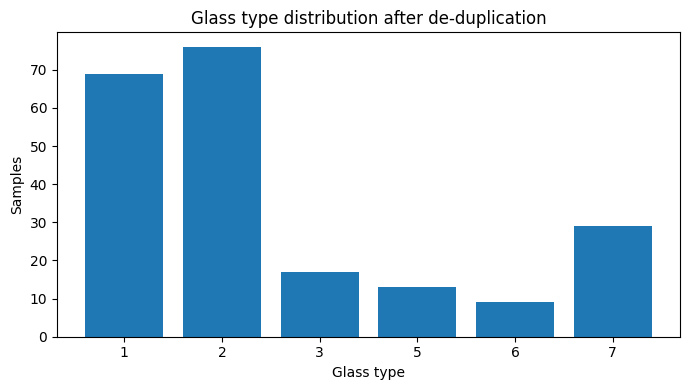

Type
1    69
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64

In [3]:
class_counts = df["Type"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(value) for value in class_counts.index], class_counts.values)
ax.set_title("Glass type distribution after de-duplication")
ax.set_xlabel("Glass type")
ax.set_ylabel("Samples")
fig.tight_layout()
fig.savefig(ASSET_DIR / "01_class_distribution.png", dpi=180)
plt.show()

class_counts

## 4. Examine unusual chemical values

I use absolute z-scores to identify observations with unusually high or low feature values.

These observations are not removed automatically. With only a little more than 200 samples, an extreme chemical composition may represent a genuine glass type rather than bad data.

The goal of this step is therefore to understand the data, not to make the dataset look more regular.


Rows by number of outlier features:
0    193
1     12
2      5
3      2
5      1
Name: count, dtype: int64

Outlier counts by feature:
Ca    7
Ba    6
Si    6
RI    3
Al    3
K     3
Fe    3
Na    2
Mg    0
dtype: int64


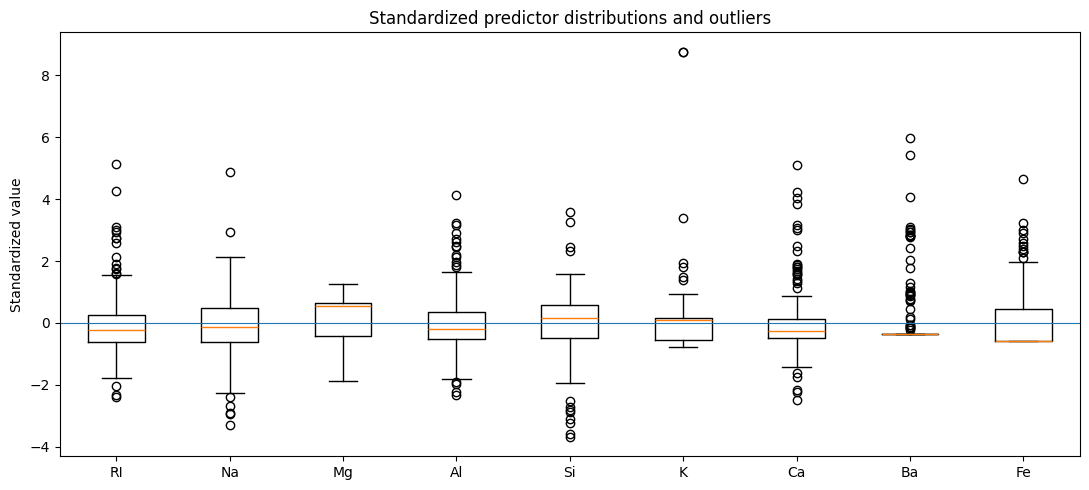

In [4]:
feature_columns = [column for column in df.columns if column != "Type"]

# Compute absolute z-scores only for predictor variables.
absolute_z_scores = np.abs(zscore(df[feature_columns], nan_policy="omit"))

outliers_per_row = (absolute_z_scores > 3).sum(axis=1)
outliers_per_feature = (absolute_z_scores > 3).sum(axis=0)

print("Rows by number of outlier features:")
print(pd.Series(outliers_per_row).value_counts().sort_index())

print()
print("Outlier counts by feature:")
print(
    pd.Series(outliers_per_feature, index=feature_columns)
    .sort_values(ascending=False)
)

# Standardize only for this visualization so variables with different scales can be compared.
# This EDA scaling is NOT reused by the models.
scaled_for_plot = StandardScaler().fit_transform(df[feature_columns])

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(
    [scaled_for_plot[:, index] for index in range(len(feature_columns))],
    tick_labels=feature_columns,
)
ax.axhline(0, linewidth=0.8)
ax.set_title("Standardized predictor distributions and outliers")
ax.set_ylabel("Standardized value")
fig.tight_layout()
fig.savefig(ASSET_DIR / "02_standardized_boxplots.png", dpi=180)
plt.show()

## 5. Examine relationships between the chemical predictors

The correlation heatmap is limited to the input variables.

The target `Type` is a category, even though it is stored with numbers such as 1, 2, 3, 5, 6 and 7. Those numbers are labels, not a continuous scale, so a Pearson correlation between `Type` and a chemical variable would not be a reliable measure of feature importance.

This view is therefore used only to understand relationships among the predictors themselves.


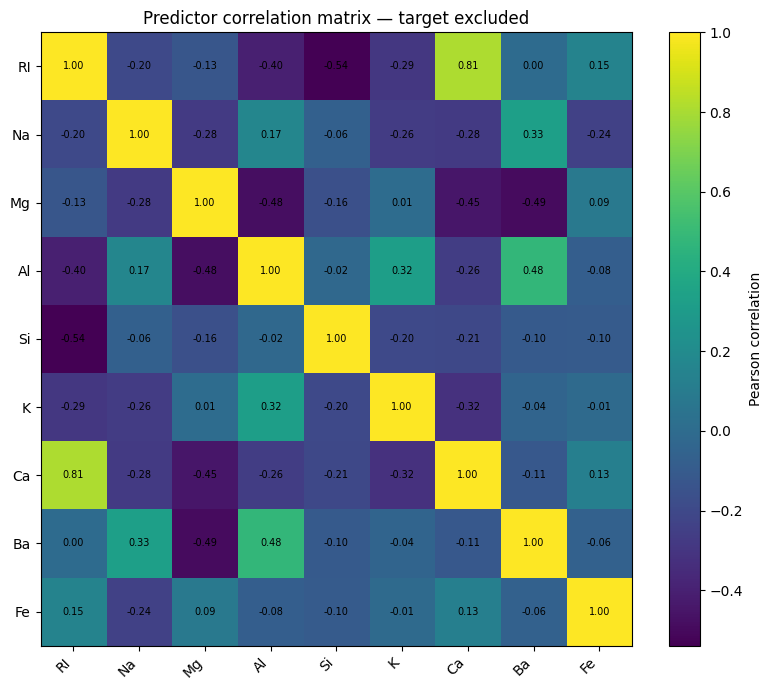

In [5]:
correlation_matrix = df[feature_columns].corr().values

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(correlation_matrix, aspect="auto")
fig.colorbar(image, ax=ax, label="Pearson correlation")

ax.set_xticks(range(len(feature_columns)))
ax.set_xticklabels(feature_columns, rotation=45, ha="right")
ax.set_yticks(range(len(feature_columns)))
ax.set_yticklabels(feature_columns)

# Print the correlation values inside each cell.
for row in range(len(feature_columns)):
    for column in range(len(feature_columns)):
        ax.text(
            column,
            row,
            f"{correlation_matrix[row, column]:.2f}",
            ha="center",
            va="center",
            fontsize=7,
        )

ax.set_title("Predictor correlation matrix : target excluded")
fig.tight_layout()
fig.savefig(ASSET_DIR / "03_predictor_correlation.png", dpi=180)
plt.show()

## 6. Compare selected chemical variables across glass types

The plots below show how selected features vary between classes.

Magnesium (`Mg`) and Barium (`Ba`) are useful examples because their distributions differ visibly across several glass types.

These plots are descriptive. They help explain the dataset, but they do not prove that a variable is causally important.


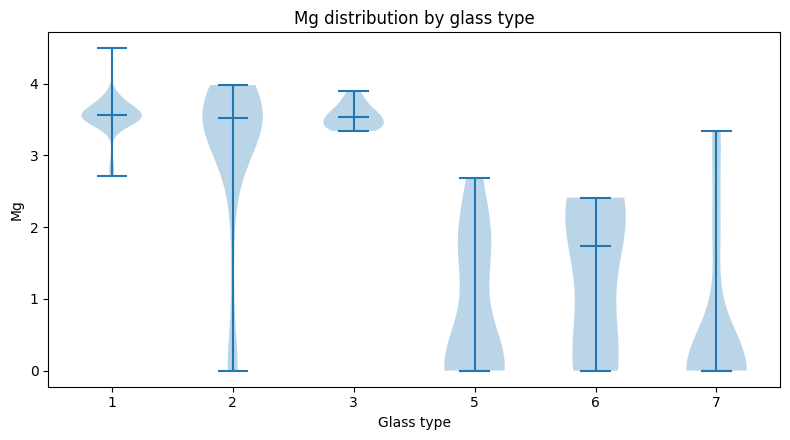

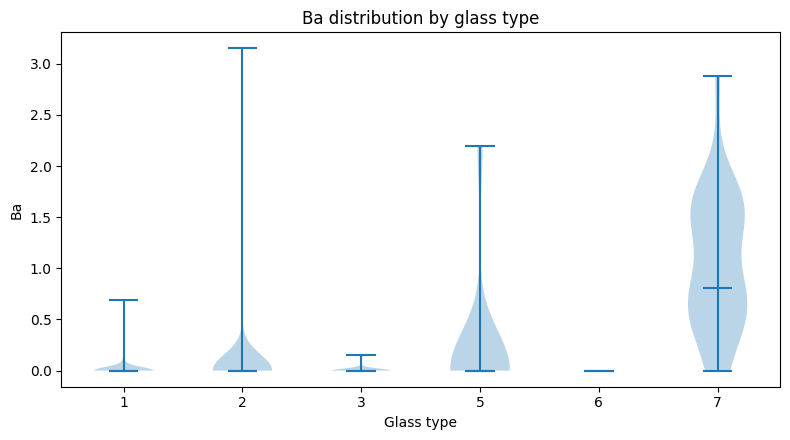

In [6]:
classes = np.array(sorted(df["Type"].unique()))

for feature in ["Mg", "Ba"]:
    values_by_class = [
        df.loc[df["Type"] == glass_type, feature].values
        for glass_type in classes
    ]

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.violinplot(values_by_class, showmedians=True)
    ax.set_xticks(range(1, len(classes) + 1))
    ax.set_xticklabels([str(glass_type) for glass_type in classes])
    ax.set_xlabel("Glass type")
    ax.set_ylabel(feature)
    ax.set_title(f"{feature} distribution by glass type")
    fig.tight_layout()
    fig.savefig(ASSET_DIR / f"04_{feature}_by_type.png", dpi=180)
    plt.show()

## 7. Evaluation strategy: stratified 5-fold cross-validation

The dataset is too small for a single train/test split to give a stable picture of performance.

I therefore use **stratified 5-fold cross-validation**:

1. the unique observations are divided into five folds while keeping the class proportions as balanced as possible;
2. four folds are used for training;
3. the remaining fold is used for evaluation;
4. the process is repeated until every observation has been evaluated once.

Inside each fold:

- scaling is learned from training data only;
- SMOTE is applied to training data only;
- the evaluation fold remains untouched.

This makes the comparison more reliable and prevents synthetic or test information from leaking into model training.


## 8. Models and evaluation metrics

I compare three models with different levels of complexity.

### Logistic Regression

A simple linear classifier. It provides a useful baseline and shows how far a straightforward decision boundary can go.

### Neural Network

A dense feed-forward network with two hidden layers and dropout. It represents the deep-learning approach explored in the academic project.

### Random Forest

An ensemble of decision trees. It can capture nonlinear relationships and interactions without requiring feature scaling.

### Main metric: Macro F1

Macro F1 gives the same importance to every class, including the rare ones. That makes it more informative than accuracy alone for this dataset.


In [7]:
X = df[feature_columns]
y = df["Type"]


def calculate_metrics(y_true, y_pred):
    """Return the metrics used to compare all models."""
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted")),
    }


def fit_predict_neural_network(X_train_outer, y_train_outer, X_test_outer, seed):
    """
    Train the neural network inside one outer cross-validation fold.

    Important: the outer test fold is never used for scaling, SMOTE,
    early stopping or model selection.
    """

    # 1) Reserve a small real validation subset from the outer training data.
    X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
        X_train_outer,
        y_train_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer,
    )

    # 2) Fit the scaler only on sub-training data.
    scaler = StandardScaler()
    X_subtrain_scaled = scaler.fit_transform(X_subtrain)
    X_validation_scaled = scaler.transform(X_validation)
    X_test_scaled = scaler.transform(X_test_outer)

    # 3) Apply SMOTE only to the scaled sub-training data.
    #    k_neighbors is adapted to the smallest class in this fold.
    smallest_class_count = int(y_subtrain.value_counts().min())
    k_neighbors = max(1, min(5, smallest_class_count - 1))

    smote = SMOTE(random_state=seed, k_neighbors=k_neighbors)
    X_balanced, y_balanced = smote.fit_resample(
        X_subtrain_scaled,
        y_subtrain,
    )

    # 4) Neural networks need class IDs from 0 to number_of_classes-1.
    label_encoder = LabelEncoder().fit(y_train_outer)
    y_balanced_encoded = label_encoder.transform(y_balanced)
    y_validation_encoded = label_encoder.transform(y_validation)

    # 5) Reset random state before building this fold's neural network.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    keras.utils.set_random_seed(seed)
    keras.backend.clear_session()

    # Original conceptual architecture: 128 -> dropout -> 64 -> dropout -> softmax.
    neural_network = keras.Sequential(
        [
            keras.layers.Input(shape=(X_balanced.shape[1],)),
            keras.layers.Dense(128, activation="relu"),
            keras.layers.Dropout(0.3),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(0.2),
            # Six outputs because only six glass types exist in this dataset.
            keras.layers.Dense(len(label_encoder.classes_), activation="softmax"),
        ]
    )

    neural_network.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        min_delta=1e-4,
    )

    history = neural_network.fit(
        X_balanced.astype("float32"),
        y_balanced_encoded,
        validation_data=(
            X_validation_scaled.astype("float32"),
            y_validation_encoded,
        ),
        epochs=120,
        batch_size=16,
        verbose=0,
        callbacks=[early_stopping],
    )

    # 6) Predict the untouched outer test fold and map IDs back to original types.
    probabilities = neural_network.predict(
        X_test_scaled.astype("float32"),
        verbose=0,
    )
    encoded_predictions = np.argmax(probabilities, axis=1)
    predictions = label_encoder.inverse_transform(encoded_predictions)

    return predictions, len(history.history["loss"])

## 9. Train and compare the models

Each model is evaluated through the same outer 5-fold split.

For Logistic Regression, scaling and SMOTE are performed inside the training pipeline.

For Random Forest, SMOTE is applied inside the training pipeline, but scaling is unnecessary because tree models are not sensitive to feature magnitude in the same way as linear models or neural networks.

For the Neural Network, preprocessing and resampling are also restricted to the training part of each fold.

This gives the three approaches a comparable evaluation framework.


In [8]:
# Create the outer cross-validation splitter.
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

fold_records = []

# Out-of-fold predictions: one final prediction for every real observation.
out_of_fold_predictions = {
    "Neural Network": np.full(len(df), -1, dtype=int),
    "Logistic Regression": np.full(len(df), -1, dtype=int),
    "Random Forest": np.full(len(df), -1, dtype=int),
}

random_forest_importances = []

for fold_number, (train_indices, test_indices) in enumerate(
    cross_validation.split(X, y)
):
    fold_seed = SEED + fold_number

    X_train = X.iloc[train_indices]
    y_train = y.iloc[train_indices]
    X_test = X.iloc[test_indices]
    y_test = y.iloc[test_indices]

    # Adapt SMOTE to the smallest class available in this fold.
    smallest_class_count = int(y_train.value_counts().min())
    k_neighbors = max(1, min(5, smallest_class_count - 1))

    # ----- Logistic Regression -----
    logistic_regression = ImbPipeline(
        [
            ("scaler", StandardScaler()),
            ("smote", SMOTE(random_state=fold_seed, k_neighbors=k_neighbors)),
            (
                "classifier",
                LogisticRegression(max_iter=3000, random_state=fold_seed),
            ),
        ]
    )

    # ----- Random Forest -----
    random_forest = ImbPipeline(
        [
            ("smote", SMOTE(random_state=fold_seed, k_neighbors=k_neighbors)),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=300,
                    random_state=fold_seed,
                    n_jobs=1,
                ),
            ),
        ]
    )

    # Fit and evaluate the two classical baselines.
    for model_name, model in [
        ("Logistic Regression", logistic_regression),
        ("Random Forest", random_forest),
    ]:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        fold_records.append(
            {
                "model": model_name,
                "fold": fold_number,
                **calculate_metrics(y_test, predictions),
            }
        )

        out_of_fold_predictions[model_name][test_indices] = predictions

        if model_name == "Random Forest":
            random_forest_importances.append(
                model.named_steps["classifier"].feature_importances_
            )

    # Fit and evaluate the neural network on the same outer fold.
    nn_predictions, epochs_run = fit_predict_neural_network(
        X_train,
        y_train,
        X_test,
        fold_seed,
    )

    fold_records.append(
        {
            "model": "Neural Network",
            "fold": fold_number,
            "epochs": epochs_run,
            **calculate_metrics(y_test, nn_predictions),
        }
    )
    out_of_fold_predictions["Neural Network"][test_indices] = nn_predictions

# Convert fold-level results into a table.
fold_results = pd.DataFrame(fold_records)

# Mean and standard deviation across the five folds.
summary_rows = {}
for model_name, group in fold_results.groupby("model"):
    summary_rows[model_name] = {
        "accuracy_mean": group["accuracy"].mean(),
        "accuracy_std": group["accuracy"].std(ddof=1),
        "balanced_accuracy_mean": group["balanced_accuracy"].mean(),
        "balanced_accuracy_std": group["balanced_accuracy"].std(ddof=1),
        "macro_f1_mean": group["macro_f1"].mean(),
        "macro_f1_std": group["macro_f1"].std(ddof=1),
        "weighted_f1_mean": group["weighted_f1"].mean(),
        "weighted_f1_std": group["weighted_f1"].std(ddof=1),
    }

summary = pd.DataFrame(summary_rows).T
summary.sort_values("macro_f1_mean", ascending=False).round(3)

,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std
Random Forest,0.756,0.046,0.766,0.064,0.735,0.068,0.759,0.047
Logistic Regression,0.625,0.053,0.730,0.070,0.668,0.075,0.632,0.060
Neural Network,0.629,0.072,0.654,0.076,0.624,0.085,0.640,0.067


## 10. Compare the results

The main question is not simply which model has the highest accuracy. It is which model performs most consistently across all six classes.

Random Forest achieves the strongest **Macro F1**, as well as the best average accuracy and balanced accuracy.

That makes it the most suitable of the three tested approaches for this dataset.


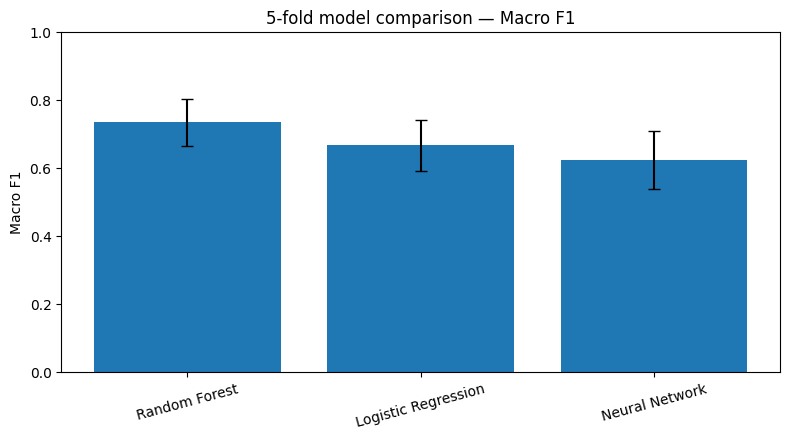

,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std
Random Forest,0.756,0.046,0.766,0.064,0.735,0.068,0.759,0.047
Logistic Regression,0.625,0.053,0.730,0.070,0.668,0.075,0.632,0.060
Neural Network,0.629,0.072,0.654,0.076,0.624,0.085,0.640,0.067


In [9]:
model_order = ["Random Forest", "Logistic Regression", "Neural Network"]
macro_f1_means = [summary.loc[name, "macro_f1_mean"] for name in model_order]
macro_f1_stds = [summary.loc[name, "macro_f1_std"] for name in model_order]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(model_order, macro_f1_means, yerr=macro_f1_stds, capsize=4)
ax.set_ylim(0, 1)
ax.set_ylabel("Macro F1")
ax.set_title("5-fold model comparison : Macro F1")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(ASSET_DIR / "05_model_comparison_macro_f1.png", dpi=180)
plt.show()

# Full numerical comparison.
display(summary.sort_values("macro_f1_mean", ascending=False).round(3))

## 11. Look at the out-of-fold confusion matrices

Every sample receives a prediction only when it belongs to an evaluation fold.

Combining those predictions produces an out-of-fold confusion matrix for the full dataset.

This makes it possible to see which glass types are confused with one another instead of relying only on a single summary score.


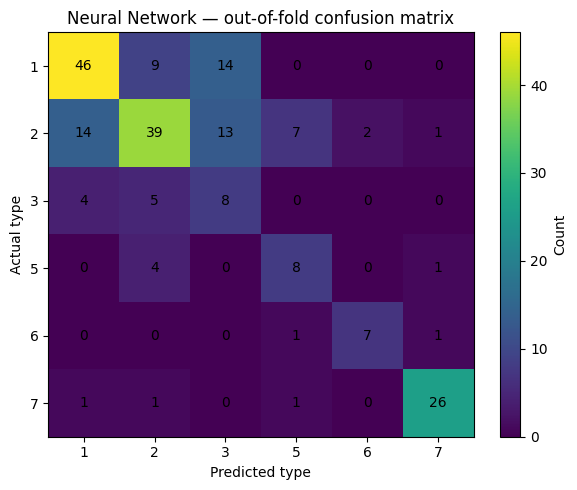

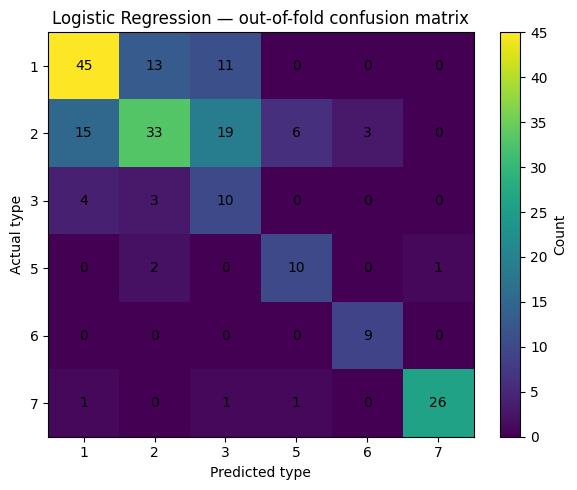

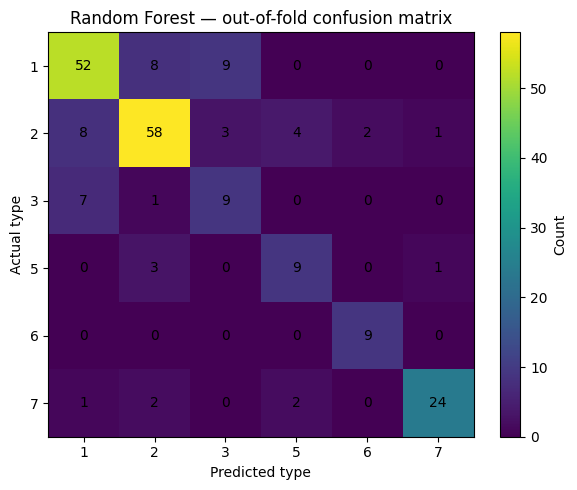

Random Forest out-of-fold classification report:
              precision    recall  f1-score   support

           1      0.765     0.754     0.759        69
           2      0.806     0.763     0.784        76
           3      0.429     0.529     0.474        17
           5      0.600     0.692     0.643        13
           6      0.818     1.000     0.900         9
           7      0.923     0.828     0.873        29

    accuracy                          0.756       213
   macro avg      0.723     0.761     0.739       213
weighted avg      0.766     0.756     0.759       213



In [10]:
for model_name in ["Neural Network", "Logistic Regression", "Random Forest"]:
    predictions = out_of_fold_predictions[model_name]
    matrix = confusion_matrix(y, predictions, labels=classes)

    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(matrix, aspect="auto")
    fig.colorbar(image, ax=ax, label="Count")

    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes)

    for row in range(len(classes)):
        for column in range(len(classes)):
            ax.text(
                column,
                row,
                str(matrix[row, column]),
                ha="center",
                va="center",
            )

    ax.set_xlabel("Predicted type")
    ax.set_ylabel("Actual type")
    ax.set_title(f"{model_name} : out-of-fold confusion matrix")
    fig.tight_layout()

    filename = model_name.lower().replace(" ", "_") + "_confusion_matrix.png"
    fig.savefig(ASSET_DIR / filename, dpi=180)
    plt.show()

print("Random Forest out-of-fold classification report:")
print(
    classification_report(
        y,
        out_of_fold_predictions["Random Forest"],
        labels=classes,
        digits=3,
        zero_division=0,
    )
)

## 12. Inspect Random Forest feature importance

Because Random Forest is the strongest model in the comparison, I inspect its feature importance to understand which chemical variables it used most often when splitting the data.

This is a **model-specific diagnostic**, not a causal explanation. A high importance means the feature was useful to this fitted forest; it does not prove that the variable is scientifically responsible for the glass type.


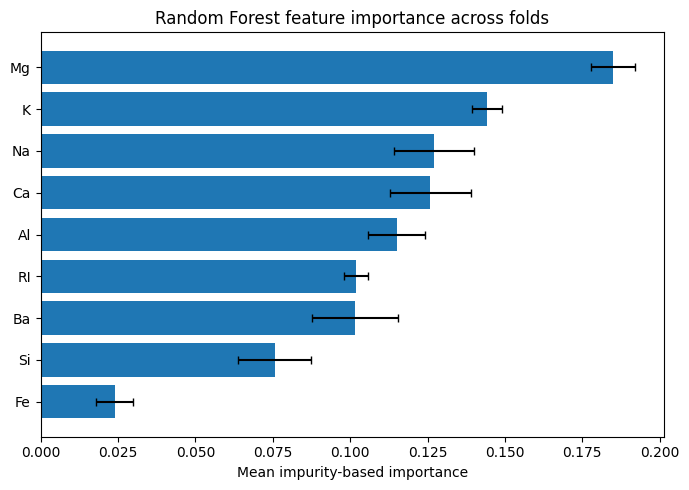

,feature,mean_importance,std_importance
2,Mg,0.1849,0.0070
5,K,0.1441,0.0049
1,Na,0.1271,0.0128
6,Ca,0.1258,0.0131
3,Al,0.1150,0.0091
0,RI,0.1020,0.0038
7,Ba,0.1016,0.0138
4,Si,0.0756,0.0117
8,Fe,0.0239,0.0061


In [11]:
# One feature-importance vector was recorded from each fold.
importance_by_fold = pd.DataFrame(
    random_forest_importances,
    columns=feature_columns,
)

feature_importance = pd.DataFrame(
    {
        "feature": feature_columns,
        "mean_importance": importance_by_fold.mean().values,
        "std_importance": importance_by_fold.std(ddof=1).values,
    }
).sort_values("mean_importance")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(
    feature_importance["feature"],
    feature_importance["mean_importance"],
    xerr=feature_importance["std_importance"],
    capsize=3,
)
ax.set_xlabel("Mean impurity-based importance")
ax.set_title("Random Forest feature importance across folds")
fig.tight_layout()
fig.savefig(ASSET_DIR / "09_rf_feature_importance.png", dpi=180)
plt.show()

display(
    feature_importance
    .sort_values("mean_importance", ascending=False)
    .round(4)
)

## Results and interpretation

Average performance across the five folds:

| Model | Accuracy | Balanced accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|---:|
| **Random Forest** | **75.6%** | **76.6%** | **0.735** | **0.759** |
| Logistic Regression | 62.5% | 73.0% | 0.668 | 0.632 |
| Neural Network | 62.9% | 65.4% | 0.624 | 0.640 |

Random Forest is the strongest model in this experiment.

Type 3 remains the hardest class, while Types 6 and 7 are recognized better. I still treat the Type 6 result cautiously because that class contains only nine real observations.

What I take from the project is simple: the neural network was worth testing, but the data did not justify its extra complexity. On this small tabular dataset, Random Forest was a better fit.

### Limits

- only 213 unique observations;
- strong class imbalance;
- no external validation dataset;
- synthetic SMOTE samples cannot replace real data;
- some glass categories overlap chemically.

### If I continued the project

I would collect more real samples, especially for the rare classes, test boosting methods, use nested cross-validation for tuning and validate the final model on an independent dataset.


## Resources

- Source dataset: `glass.csv`
- Main technologies: Python, pandas, scikit-learn, imbalanced-learn, Keras
- Models compared: Logistic Regression, Neural Network, Random Forest
- Evaluation: stratified 5-fold cross-validation

This public notebook documents the model comparison and evaluation used in the portfolio case study.


## 14. Save the key results

The final cell exports fold-level metrics, summary results, out-of-fold confusion matrices and Random Forest feature importance.

Keeping these results in a machine-readable file makes it easier to reproduce the analysis and keep future documentation consistent with the executed notebook.


In [12]:
# Metrics computed from the complete set of out-of-fold predictions.
out_of_fold_metrics = {
    model_name: calculate_metrics(y, predictions)
    for model_name, predictions in out_of_fold_predictions.items()
}

out_of_fold_confusion_matrices = {
    model_name: confusion_matrix(
        y,
        predictions,
        labels=classes,
    ).tolist()
    for model_name, predictions in out_of_fold_predictions.items()
}

export = {
    "raw_rows": int(len(df_raw)),
    "unique_rows": int(len(df)),
    "exact_duplicates_removed": int(len(df_raw) - len(df)),
    "classes": [int(value) for value in classes],
    "class_counts": {
        str(class_id): int(count)
        for class_id, count in y.value_counts().sort_index().items()
    },
    "cv_folds": 5,
    "fold_results": fold_records,
    "summary": {
        model_name: {
            **{
                metric + "_mean": float(group[metric].mean())
                for metric in [
                    "accuracy",
                    "balanced_accuracy",
                    "macro_f1",
                    "weighted_f1",
                ]
            },
            **{
                metric + "_std": float(group[metric].std(ddof=1))
                for metric in [
                    "accuracy",
                    "balanced_accuracy",
                    "macro_f1",
                    "weighted_f1",
                ]
            },
        }
        for model_name, group in fold_results.groupby("model")
    },
    "out_of_fold_metrics": out_of_fold_metrics,
    "out_of_fold_confusion_matrices": out_of_fold_confusion_matrices,
}

with open(ASSET_DIR / "glass_canonical_results.json", "w") as file:
    json.dump(export, file, indent=2)

summary.to_csv(ASSET_DIR / "model_comparison.csv")
feature_importance.sort_values(
    "mean_importance",
    ascending=False,
).to_csv(ASSET_DIR / "rf_feature_importance.csv", index=False)

print(json.dumps(export["summary"], indent=2))

{
  "Logistic Regression": {
    "accuracy_mean": 0.6246954595791805,
    "balanced_accuracy_mean": 0.7298137973137971,
    "macro_f1_mean": 0.6677693728893128,
    "weighted_f1_mean": 0.6318519344632202,
    "accuracy_std": 0.052870448548357145,
    "balanced_accuracy_std": 0.07025608127867516,
    "macro_f1_std": 0.07510578410786706,
    "weighted_f1_std": 0.059661936861473586
  },
  "Neural Network": {
    "accuracy_mean": 0.6293466223698783,
    "balanced_accuracy_mean": 0.6537225274725273,
    "macro_f1_mean": 0.6244530834410439,
    "weighted_f1_mean": 0.6397412005319472,
    "accuracy_std": 0.07198824406685682,
    "balanced_accuracy_std": 0.07564011491977915,
    "macro_f1_std": 0.08485890818969809,
    "weighted_f1_std": 0.06741814448711246
  },
  "Random Forest": {
    "accuracy_mean": 0.7562569213732004,
    "balanced_accuracy_mean": 0.7655021367521367,
    "macro_f1_mean": 0.7352184506467043,
    "weighted_f1_mean": 0.7593556651081932,
    "accuracy_std": 0.0461250613087019